# Problem Set 5 - Neural Networks

Submitted by: <b>Lanuzo, Jessica Mae T. | BSCS-2A </b>
***
Download a classification dataset from UCI Machine Learning Repository. Then explore the dataset using the code implementation of Neural Network explained in the link below:
- https://www.bmc.com/blogs/keras-neural-network-classification/


Write a one-page report containing two (2) sections describing the Dataset and the Classification Result. Submit a zip file named as PS5_LastName_Section.zip containing your code, the dataset, and the report file named PS5_LastName_Section.pdf.


     The Dataset: Auction Verification Data Set

> The dataset was created as part of a scientific study. The goal was to find out whether one could replace costly verification of complex process models (here: simultaneous multi-round auctions, as used for auctioning frequency spectra) with predictions of the outcome. (© UCI MLR). The dataset classifies the Verification result (True or False) for the 7 given fields in a verification run.

> Repository URL: https://archive.ics.uci.edu/dataset/713/auction+verification.

***
### **Creating a Neural Network for the Auction Verification Dataset**


#### Importing libraries

In [362]:
import tensorflow as tf
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from keras.models import Sequential
from keras.layers import Dense
from tensorflow.keras.layers import Dropout

#### Preparing the dataset

In [162]:
data = pd.read_csv('auctionv_ds.csv', delimiter=',')

data['verification.result']=data['verification.result'].astype(int)
labels=data['verification.result']
features = data.iloc[:,0:7]

#### Dataset information

##### Data descriptions

In [163]:
data.describe()

,process.b1.capacity,process.b2.capacity,process.b3.capacity,process.b4.capacity,property.price,property.product,property.winner,verification.result,verification.time
count,2043.000000,2043.000000,2043.000000,2043.000000,2043.000000,2043.000000,2043.000000,2043.000000,2043.000000
mean,1.000000,2.093979,1.883994,0.587861,71.473324,3.252080,0.455213,0.128243,7336.944574
std,0.816696,0.811269,0.320310,0.492340,8.048740,1.804225,1.062828,0.334442,10375.393650
min,0.000000,0.000000,1.000000,0.000000,59.000000,1.000000,0.000000,0.000000,77.916667
25%,0.000000,1.000000,2.000000,0.000000,65.000000,2.000000,0.000000,0.000000,546.818910
50%,1.000000,2.000000,2.000000,1.000000,70.000000,3.000000,0.000000,0.000000,1316.983333
75%,2.000000,3.000000,2.000000,1.000000,78.000000,5.000000,0.000000,0.000000,10876.638889
max,2.000000,3.000000,2.000000,1.000000,90.000000,6.000000,4.000000,1.000000,44130.520833


In [164]:
data.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2043 entries, 0 to 2042
Data columns (total 9 columns):
 #   Column               Non-Null Count  Dtype  
---  ------               --------------  -----  
 0   process.b1.capacity  2043 non-null   int64  
 1   process.b2.capacity  2043 non-null   int64  
 2   process.b3.capacity  2043 non-null   int64  
 3   process.b4.capacity  2043 non-null   int64  
 4   property.price       2043 non-null   int64  
 5   property.product     2043 non-null   int64  
 6   property.winner      2043 non-null   int64  
 7   verification.result  2043 non-null   int64  
 8   verification.time    2043 non-null   float64
dtypes: float64(1), int64(8)
memory usage: 143.8 KB


C:\Users\Jessica\AppData\Local\Temp\ipykernel_13240\1756502356.py:2: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(x='verification.result', data=data, palette='bright')


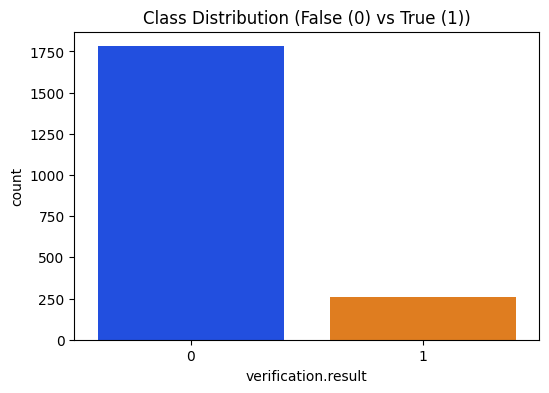

In [165]:
plt.figure(figsize=(6, 4))
sns.countplot(x='verification.result', data=data, palette='bright')
plt.title('Class Distribution (False (0) vs True (1))')
plt.show()

##### Data Correlation

<Axes: >

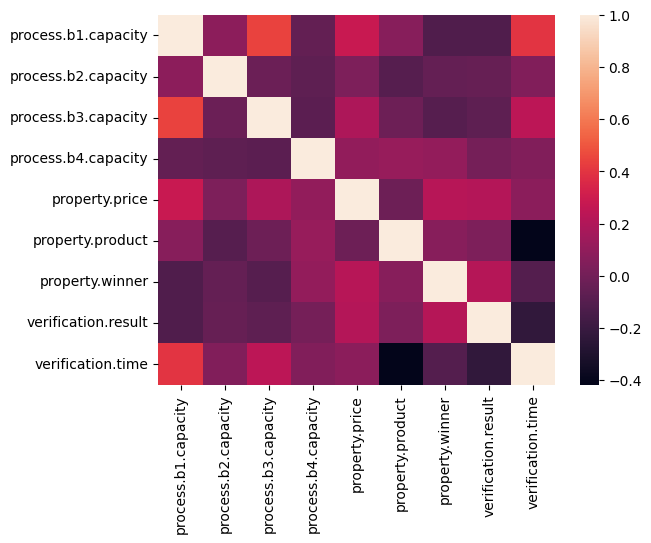

In [166]:
import seaborn as sns
import matplotlib as plt
corr = data.corr()
sns.heatmap(corr, 
xticklabels=corr.columns.values,
yticklabels=corr.columns.values)

In [167]:
data['process.b3.capacity'].corr( data["process.b1.capacity"])

np.float64(0.4436708845761661)

In [169]:
data["process.b1.capacity"].corr(data["property.price"])

np.float64(0.2855580966290086)

#### Splitting the data

In [170]:
X=features
y=np.ravel(labels)
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.33, random_state=42) 

##### Normalizing the values

In [171]:
scaler = StandardScaler().fit(X_train)
X_train = scaler.transform(X_train)
X_test = scaler.transform(X_test)  

X_train= pd.DataFrame(X_train)
X_train.describe().round(3)

,0,1,2,3,4,5,6
count,1368.000,1368.000,1368.000,1368.000,1368.000,1368.000,1368.000
mean,-0.000,-0.000,0.000,0.000,0.000,0.000,-0.000
std,1.000,1.000,1.000,1.000,1.000,1.000,1.000
min,-1.240,-2.504,-2.927,-1.199,-1.521,-1.236,-0.427
25%,-1.240,-1.294,0.342,-1.199,-0.779,-0.687,-0.427
50%,-0.013,-0.084,0.342,0.834,-0.161,-0.137,-0.427
75%,1.215,1.126,0.342,0.834,0.828,0.962,-0.427
max,1.215,1.126,0.342,0.834,2.312,1.512,3.307


#### Building the model (following the example first)

In [175]:
model = Sequential()

model.add(Dense(8, activation='relu', input_shape=(7,)))
model.add(Dense(8, activation='relu'))
model.add(Dense(1, activation='sigmoid'))

model.compile(loss='binary_crossentropy',
optimizer='sgd',
metrics=['accuracy'])

model.fit(X_train, y_train, validation_split=0.2, epochs=10, batch_size=1, verbose=1)

Epoch 1/10


c:\Users\Jessica\AppData\Local\Programs\Python\Python311\Lib\site-packages\keras\src\layers\core\dense.py:87: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


1094/1094 ━━━━━━━━━━━━━━━━━━━━ 5s 3ms/step - accuracy: 0.8730 - loss: 0.4884 - val_accuracy: 0.8650 - val_loss: 0.3967
Epoch 2/10
1094/1094 ━━━━━━━━━━━━━━━━━━━━ 3s 3ms/step - accuracy: 0.8676 - loss: 0.3705 - val_accuracy: 0.8650 - val_loss: 0.3551
Epoch 3/10
1094/1094 ━━━━━━━━━━━━━━━━━━━━ 3s 3ms/step - accuracy: 0.8870 - loss: 0.3163 - val_accuracy: 0.8650 - val_loss: 0.3457
Epoch 4/10
1094/1094 ━━━━━━━━━━━━━━━━━━━━ 3s 3ms/step - accuracy: 0.8790 - loss: 0.3191 - val_accuracy: 0.8650 - val_loss: 0.3401
Epoch 5/10
1094/1094 ━━━━━━━━━━━━━━━━━━━━ 3s 3ms/step - accuracy: 0.8749 - loss: 0.3173 - val_accuracy: 0.8650 - val_loss: 0.3488
Epoch 6/10
1094/1094 ━━━━━━━━━━━━━━━━━━━━ 4s 3ms/step - accuracy: 0.8866 - loss: 0.2990 - val_accuracy: 0.8650 - val_loss: 0.3312
Epoch 7/10
1094/1094 ━━━━━━━━━━━━━━━━━━━━ 3s 3ms/step - accuracy: 0.8849 - loss: 0.2886 - val_accuracy: 0.8650 - val_loss: 0.3176
Epoch 8/10
1094/1094 ━━━━━━━━━━━━━━━━━━━━ 3s 3ms/step - accuracy: 0.8799 - loss: 0.2759 - val_accurac

#### Fine-tuned model

In [359]:
model = Sequential()

model.add(Dense(128, activation='relu', input_shape=(7,)))
model.add(Dropout(0.5))
model.add(Dense(64, activation='relu'))
model.add(Dropout(0.4))

model.add(Dense(1, activation='sigmoid'))

model.compile(loss='binary_crossentropy',
optimizer='adam',
metrics=['accuracy'])

model.fit(X_train, y_train, validation_split=0.2, epochs=50, batch_size=16, verbose=1)

c:\Users\Jessica\AppData\Local\Programs\Python\Python311\Lib\site-packages\keras\src\layers\core\dense.py:87: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


Epoch 1/50
69/69 ━━━━━━━━━━━━━━━━━━━━ 3s 12ms/step - accuracy: 0.7137 - loss: 0.5722 - val_accuracy: 0.8650 - val_loss: 0.3869
Epoch 2/50
69/69 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.8718 - loss: 0.3579 - val_accuracy: 0.8650 - val_loss: 0.3569
Epoch 3/50
69/69 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.8708 - loss: 0.3436 - val_accuracy: 0.8650 - val_loss: 0.3410
Epoch 4/50
69/69 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - accuracy: 0.8627 - loss: 0.3510 - val_accuracy: 0.8650 - val_loss: 0.3300
Epoch 5/50
69/69 ━━━━━━━━━━━━━━━━━━━━ 1s 7ms/step - accuracy: 0.8588 - loss: 0.3438 - val_accuracy: 0.8650 - val_loss: 0.3253
Epoch 6/50
69/69 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.8690 - loss: 0.3047 - val_accuracy: 0.8650 - val_loss: 0.3269
Epoch 7/50
69/69 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.8847 - loss: 0.2875 - val_accuracy: 0.8650 - val_loss: 0.3139
Epoch 8/50
69/69 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.8660 - loss: 0.3166 - val_accuracy: 0.8650 - val_loss

#### Results

In [360]:
model.summary()

Model: "sequential_275"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense_848 (Dense)               │ (None, 128)            │         1,024 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_388 (Dropout)           │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_849 (Dense)               │ (None, 64)             │         8,256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_389 (Dropout)           │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_850 (Dense)               │ (None, 1)              │            65 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 28,037 (109.52 KB)

 Trainable params: 9,345 (36.50 KB)

 Non-trainable params: 0 (0.00 B)

 Optimizer params: 18,692 (73.02 KB)

In [361]:
y_pred = model.predict(X_test)

score = model.evaluate(X_test, y_test,verbose=1)
print(score)

22/22 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step
22/22 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.9039 - loss: 0.2675 
[0.26310232281684875, 0.9066666960716248]
